# Análisis exploratorio de incendios forestales en España (1968–2023)

El objetivo de este proyecto es estudiar la evolución de los incendios forestales registrados en España, su distribución territorial y temporal, sus posibles causas y la superficie afectada. El análisis también servirá para preparar los datos de una aplicación interactiva en Streamlit.

## 0. Preparación del entorno

Importo las librerías que utilizaré durante la exploración y el tratamiento de los datos.

In [153]:
import pandas as pd
import matplotlib
import datetime 

print("Todo listo")

Todo listo


## 1. Conocer el conjunto de datos

Comienzo cargando el archivo original para comprobar que se lee correctamente y observar cómo están organizados los registros.

In [154]:
incendios = pd.read_csv("datos/incendios.csv")

incendios.head(5)

,id,superficie,fecha,lat,lng,latlng_explicit,idcomunidad,idprovincia,idmunicipio,municipio,...,causa_supuesta,causa_desc,muertos,heridos,time_ctrl,time_ext,personal,medios,gastos,perdidas
0,1968290001,14.0,1968-01-01,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,40,0,0,NaN,360.0,0,0,0.0,0.0
1,1968430003,3.0,1968-01-03,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,0,0,0,NaN,60.0,0,0,0.0,0.0
2,1968290006,2.0,1968-01-06,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,0,0,0,NaN,120.0,0,0,0.0,0.0
3,1968120007,8.2,1968-01-07,NaN,NaN,NaN,9,12,0,INDETERMINADO,...,1,20,0,0,NaN,120.0,0,0,0.0,0.0
4,1968430016,600.0,1968-01-07,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,20,0,0,NaN,1440.0,35,1,0.0,0.0


Reviso el tamaño del conjunto de datos y la información general de sus columnas. Estas comprobaciones permiten conocer los tipos de datos y detectar posibles problemas antes de empezar la limpieza.

In [155]:
incendios.shape

(296839, 21)

In [156]:
incendios.info()

<class 'pandas.DataFrame'>
RangeIndex: 296839 entries, 0 to 296838
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               296839 non-null  int64  
 1   superficie       296839 non-null  float64
 2   fecha            296839 non-null  str    
 3   lat              242439 non-null  float64
 4   lng              242439 non-null  float64
 5   latlng_explicit  242446 non-null  float64
 6   idcomunidad      296839 non-null  int64  
 7   idprovincia      296839 non-null  int64  
 8   idmunicipio      296839 non-null  int64  
 9   municipio        296839 non-null  str    
 10  causa            296839 non-null  int64  
 11  causa_supuesta   296839 non-null  int64  
 12  causa_desc       296839 non-null  int64  
 13  muertos          296839 non-null  int64  
 14  heridos          296839 non-null  int64  
 15  time_ctrl        143055 non-null  float64
 16  time_ext         296838 non-null  float64
 17  pe

El archivo original contiene **296.839 filas y 21 columnas**. Las variables combinan información numérica y textual sobre cada incendio.

Para centrar el estudio en las características relevantes, selecciono las columnas que voy a utilizar y les asigno nombres más claros. Esta selección elimina **variables**, no incendios.

In [157]:
incendios = incendios[["superficie", "fecha", "lat", "lng", "latlng_explicit", "idcomunidad", "idprovincia", "municipio", "causa", "causa_supuesta", "muertos", "heridos", "time_ctrl", "time_ext", "personal", "medios", "gastos", "perdidas"]]

In [158]:
incendios.columns = ["hectareas", "fecha", "latitud", "longitud", "ubicación exacta", "comunidad", "provincia", "municipio", "causa", "confirmacion causa", "muertos", "heridos", "tiempo de control", "tiempo de extincion", "personal", "medios", "gastos", "perdidas"]

incendios.head(5)       

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de control,tiempo de extincion,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,4,29,INDETERMINADO,2,1,0,0,NaN,360.0,0,0,0.0,0.0
1,3.0,1968-01-03,NaN,NaN,NaN,2,43,INDETERMINADO,5,1,0,0,NaN,60.0,0,0,0.0,0.0
2,2.0,1968-01-06,NaN,NaN,NaN,4,29,INDETERMINADO,5,1,0,0,NaN,120.0,0,0,0.0,0.0
3,8.2,1968-01-07,NaN,NaN,NaN,9,12,INDETERMINADO,3,1,0,0,NaN,120.0,0,0,0.0,0.0
4,600.0,1968-01-07,NaN,NaN,NaN,2,43,INDETERMINADO,3,1,0,0,NaN,1440.0,35,1,0.0,0.0


## 2. Valores ausentes y selección de variables

Una vez seleccionadas y renombradas las columnas, compruebo cuántos valores faltan en cada una y qué porcentaje representan sobre el total de registros. Así puedo decidir qué información conservar y qué limitaciones debo tener en cuenta.

In [159]:
incendios.isna().sum()

hectareas                   0
fecha                       0
latitud                 54400
longitud                54400
ubicación exacta        54393
comunidad                   0
provincia                   0
municipio                   0
causa                       0
confirmacion causa          0
muertos                     0
heridos                     0
tiempo de control      153784
tiempo de extincion         1
personal                    0
medios                      0
gastos                      0
perdidas                    0
dtype: int64

In [160]:
round(incendios.isna().sum() / len(incendios) * 100 , 1)

hectareas               0.0
fecha                   0.0
latitud                18.3
longitud               18.3
ubicación exacta       18.3
comunidad               0.0
provincia               0.0
municipio               0.0
causa                   0.0
confirmacion causa      0.0
muertos                 0.0
heridos                 0.0
tiempo de control      51.8
tiempo de extincion     0.0
personal                0.0
medios                  0.0
gastos                  0.0
perdidas                0.0
dtype: float64

Las columnas de **latitud**, **longitud** y **ubicación exacta** presentan aproximadamente un **18,3 % de valores ausentes** en esta revisión.

Decido **conservar esos incendios**: aunque no puedan localizarse en un mapa, pueden aportar información útil al análisis histórico. En la aplicación se excluirán únicamente de la representación geográfica.

También reviso el tiempo de control para valorar si resulta suficientemente completo y fiable como variable de análisis.

In [161]:
print("Tiempo de control de incendios: Mediana", incendios["tiempo de control"].median() , "Media", incendios["tiempo de control"].mean().round(1) )



Tiempo de control de incendios: Mediana 140.0 Media 290.6


In [162]:
incendios = incendios.drop(columns = ["tiempo de control", "tiempo de extincion"])  # Esta columna es interesante pero es demasiado incompleta, y para medir el tiempo tenemos la columna de tiempo de extinción



La media y la mediana del tiempo de control presentan una diferencia considerable, lo que sugiere una distribución asimétrica. Junto con los valores ausentes y la falta de utilidad de estas variables para los objetivos del proyecto, decido retirar **tiempo de control** y **tiempo de extinción**.

No sustituyo sus valores ausentes por una media o mediana: hacerlo introduciría tiempos estimados sin una justificación suficiente. Después vuelvo a comprobar los nulos de las columnas conservadas.

In [163]:
incendios.isna().sum()

hectareas                 0
fecha                     0
latitud               54400
longitud              54400
ubicación exacta      54393
comunidad                 0
provincia                 0
municipio                 0
causa                     0
confirmacion causa        0
muertos                   0
heridos                   0
personal                  0
medios                    0
gastos                    0
perdidas                  0
dtype: int64

## 3. Registros repetidos

Antes de continuar, compruebo si existen filas idénticas en las variables conservadas. La coincidencia exacta de una fila **no demuestra necesariamente** que se trate del mismo incendio: el conjunto de datos no dispone aquí de un identificador único que permita confirmarlo.

In [164]:
print("Filas repetidas", incendios.duplicated().sum())

Filas repetidas 974


In [165]:
incendios = incendios.drop_duplicates()

print("Quedan", len(incendios), "incendios")

Quedan 295865 incendios


La comprobación identifica **974 filas repetidas** según las columnas disponibles en esta versión del análisis. Decido conservar una sola aparición de cada fila idéntica para evitar posibles dobles contabilizaciones.

**Limitación:** algunos registros iguales podrían corresponder a sucesos distintos. La eliminación afecta a una proporción pequeña del total, pero conviene tener presente esta incertidumbre al interpretar los resultados.

## 4. Distribución de las variables numéricas

Utilizo las estadísticas descriptivas para conocer el rango, la tendencia central y la dispersión de las variables numéricas. Me interesa especialmente identificar valores extremos y diferencias entre medias y medianas.

In [166]:
incendios.describe()

,hectareas,latitud,longitud,ubicación exacta,comunidad,provincia,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
count,295865.000000,242404.000000,242404.000000,242411.000000,295865.000000,295865.000000,295865.000000,295865.000000,295865.000000,295865.000000,295865.000000,295865.000000,2.958650e+05,2.958650e+05
mean,27.372973,41.686486,-5.722218,0.372891,7.306660,27.595099,3.874017,0.813888,0.000669,0.006489,22.329130,2.133182,6.699719e+02,8.620660e+03
std,252.687803,1.952415,2.549838,0.483575,5.450105,11.791813,1.059536,0.389198,0.057314,0.166129,46.040569,5.272350,1.489301e+04,2.442590e+05
min,1.000000,27.707179,-18.148781,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,1.800000,40.854302,-7.520687,0.000000,3.000000,17.000000,4.000000,1.000000,0.000000,0.000000,5.000000,0.000000,0.000000e+00,0.000000e+00
50%,3.500000,42.340569,-6.285157,0.000000,5.000000,32.000000,4.000000,1.000000,0.000000,0.000000,12.000000,1.000000,0.000000e+00,0.000000e+00
75%,10.190000,43.060419,-4.381793,1.000000,12.000000,36.000000,5.000000,1.000000,0.000000,0.000000,25.000000,2.000000,0.000000e+00,1.800000e+02
max,29867.000000,43.765502,4.274832,1.000000,18.000000,51.000000,6.000000,1.000000,20.000000,30.000000,3612.000000,438.000000,2.793745e+06,5.484489e+07


La tabla descriptiva permite detectar valores máximos llamativos y variables con distribuciones muy desiguales. Antes de considerarlos errores, conviene contrastarlos con el contexto de los incendios y revisar qué representa cada columna.

Empiezo por la superficie quemada: comparo su media y mediana y observo su distribución mediante un histograma.

In [167]:
print("Hectáreas quemadas: Mediana", int(incendios["hectareas"].median()) , "Media", int(incendios["hectareas"].mean()) )

Hectáreas quemadas: Mediana 3 Media 27


<Axes: title={'center': 'Hectáreas quemadas'}, ylabel='Frequency'>

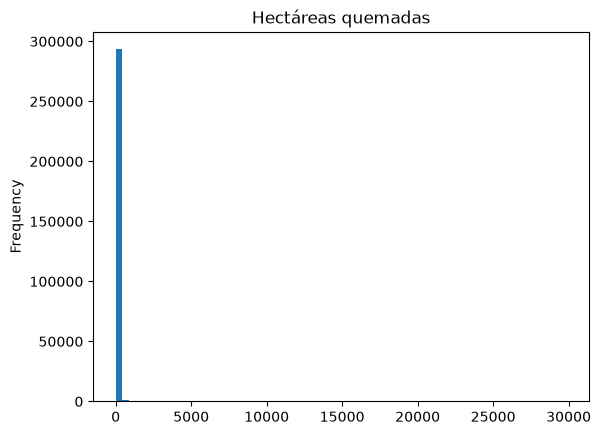

In [168]:
incendios["hectareas"].plot(kind= "hist", bins = 70, title = "Hectáreas quemadas")  

La diferencia entre media y mediana, junto con el histograma, sugiere que predominan los incendios de pequeña superficie y que unos pocos sucesos de gran magnitud elevan la media. Por ello, **la media por sí sola no describe bien un incendio típico**.

## 5. Revisión de valores extremos y calidad de los datos

Ordeno los registros por superficie quemada y utilizo un diagrama de caja para explorar valores extremos. Un incendio muy grande no es necesariamente un dato incorrecto: puede ser un suceso real y relevante para el estudio.

In [169]:
incendios.sort_values("hectareas", ascending = False).head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
218907,29867.0,2004-07-27,37.691760,-6.599990,1.0,4,21,MINAS DE RIOTINTO,4,0,0,1,1504,123,0.0,4488390.0
263245,28879.1,2012-06-28,39.269115,-0.955787,1.0,9,46,CORTES DE PALLÁS,3,0,1,0,540,146,0.0,12607966.0
139510,28213.3,1994-07-02,40.637450,-0.527527,0.0,10,44,VILLARLUENGO,1,1,0,0,1063,64,95861.0,23637217.0
139555,25579.0,1994-07-04,38.568266,-1.727008,0.0,11,2,HELLÍN,2,1,0,0,936,137,974753.0,2317275.0
139623,25430.0,1994-07-04,39.224837,-0.845232,0.0,9,46,MILLARES,1,1,9,0,423,34,0.0,6350780.0


In [170]:
incendios.sort_values("hectareas", ascending = True).head(5) 

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
9,1.0,1968-01-10,NaN,NaN,NaN,17,49,INDETERMINADO,2,1,0,0,0,0,0.0,0.0
181705,1.0,1999-08-20,41.355083,-6.287405,0.0,17,49,VILLAR DEL BUEY,4,1,0,0,20,0,0.0,0.0
29,1.0,1968-01-23,NaN,NaN,NaN,10,44,INDETERMINADO,2,1,0,0,0,0,0.0,0.0
296802,1.0,2022-12-30,43.348351,-4.904999,1.0,5,33,CABRALES,4,1,0,0,3,2,0.0,0.0
296803,1.0,2022-12-31,43.246300,-6.138801,1.0,5,33,YERNES Y TAMEZA,4,1,0,0,3,2,0.0,0.0


<Axes: title={'center': 'Hectareas quemadas'}>

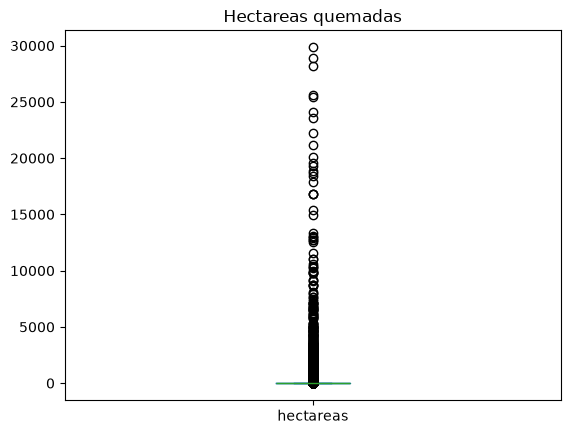

In [171]:
incendios["hectareas"].plot(kind= "box", title = "Hectareas quemadas")

Los registros de mayor y menor superficie y el diagrama de caja refuerzan la idea de una distribución muy asimétrica. Mantengo los valores extremos mientras no exista evidencia de que sean errores de registro.

In [172]:
print("Filas vacías en gasto:", round(len(incendios[incendios["gastos"] == 0]) / len(incendios) * 100, 1), "%. Filas vacás en perdidas:", round(len(incendios[incendios["perdidas"] == 0]) / len(incendios) * 100, 1), "%" )

Filas vacías en gasto: 83.6 %. Filas vacás en perdidas: 57.4 %


Las columnas **gastos** y **pérdidas** contienen numerosos valores iguales a cero. No puedo asegurar que todos representen ausencia real de costes: algunos podrían indicar información no registrada.

Por ello, cualquier resultado económico debe interpretarse con cautela. Además, los importes históricos pueden no ser directamente comparables entre años si no están ajustados por inflación.

A continuación, preparo las variables categóricas para que los resultados sean más fáciles de leer.

In [173]:
incendios["comunidad"] = incendios["comunidad"].replace({
    1: "País Vasco",
    2: "Cataluña",
    3: "Galicia",
    4: "Andalucía",
    5: "Asturias",
    6: "Cantabria",
    7: "La Rioja",
    8: "Murcia",
    9: "Comunidad Valenciana",
    10: "Aragón",
    11: "Castilla-La Mancha",
    12: "Islas Canarias",
    13: "Navarra",
    14: "Extremadura",
    15: "Islas Baleares",
    16: "Madrid",
    17: "Castilla y León",
    18: "Ceuta y Melilla"
    
})

incendios.head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,Andalucía,29,INDETERMINADO,2,1,0,0,0,0,0.0,0.0
1,3.0,1968-01-03,NaN,NaN,NaN,Cataluña,43,INDETERMINADO,5,1,0,0,0,0,0.0,0.0
2,2.0,1968-01-06,NaN,NaN,NaN,Andalucía,29,INDETERMINADO,5,1,0,0,0,0,0.0,0.0
3,8.2,1968-01-07,NaN,NaN,NaN,Comunidad Valenciana,12,INDETERMINADO,3,1,0,0,0,0,0.0,0.0
4,600.0,1968-01-07,NaN,NaN,NaN,Cataluña,43,INDETERMINADO,3,1,0,0,35,1,0.0,0.0


Los códigos numéricos de comunidad autónoma, provincia y causa son poco intuitivos en tablas y gráficas. Los sustituyo por etiquetas descriptivas mediante diccionarios de equivalencias, manteniendo el significado de cada categoría.

In [174]:
incendios["provincia"] = incendios["provincia"].replace({
    1: "Álava",
    2: "Albacete",
    3: "Alicante",
    4: "Almería",
    5: "Ávila",
    6: "Badajoz",
    7: "Islas Baleares",
    8: "Barcelona",
    9: "Burgos",
    10: "Cáceres",
    11: "Cádiz",
    12: "Castellón",
    13: "Ciudad Real",
    14: "Córdoba",
    15: "A Coruña",
    16: "Cuenca",
    17: "Girona",
    18: "Granada",
    19: "Guadalajara",
    20: "Gipuzkoa",
    21: "Huelva",
    22: "Huesca",
    23: "Jaén",
    24: "León",
    25: "Lleida",
    26: "La Rioja",
    27: "Lugo",
    28: "Madrid",
    29: "Málaga",
    30: "Murcia",
    31: "Navarra",
    32: "Ourense",
    33: "Asturias",
    34: "Palencia",
    35: "Las Palmas",
    36: "Pontevedra",
    37: "Salamanca",
    38: "Santa Cruz de Tenerife",
    39: "Cantabria",
    40: "Segovia",
    41: "Sevilla",
    42: "Soria",
    43: "Tarragona",
    44: "Teruel",
    45: "Toledo",
    46: "Valencia",
    47: "Valladolid",
    48: "Bizkaia",
    49: "Zamora",
    50: "Zaragoza",
    51: "Ceuta",
    52: "Melilla"
})


incendios.tail(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
296838,1.8,2023-12-08,37.608123,-1.012078,1.0,Murcia,Murcia,CARTAGENA,4,0,0,0,10,2,0.0,0.0


In [175]:
incendios["causa"] = incendios["causa"].replace({
    1: "Causa Natural",
    2: "Negligencias y accidentes",
    3: "Intencionados",
    4: "Causa desconocida",
    5: "Reproducciones",
    6: "Otras causas humanas"
})

incendios.head(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,1,0,0,0,0,0.0,0.0


Completo la interpretación de las variables categóricas: convierto los códigos de **ubicación exacta** y **confirmación de la causa** en etiquetas legibles. Estas variables requieren atención porque una causa supuesta no tiene el mismo grado de certeza que una confirmada.

In [176]:
incendios["ubicación exacta"] = incendios["ubicación exacta"].replace({
    1: "Si",
    0: "Municipio más cercano"
})

In [177]:
incendios["confirmacion causa"] = incendios["confirmacion causa"].replace({
    1: "Supuesta",
    0: "Confirmada"
})

incendios.head(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0


Para analizar la evolución temporal, preparo variables derivadas de la fecha. Separar **año** y **mes** facilitará las comparaciones y la creación de gráficas.

In [178]:
incendios.insert(2, "año", pd.to_datetime(incendios["fecha"]).dt.year)

incendios.head(1)

,hectareas,fecha,año,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,1968,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0


In [179]:
incendios.insert(3, "mes", pd.to_datetime(incendios["fecha"]).dt.month)

incendios.head(1)

,hectareas,fecha,año,mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,1968,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0


In [180]:
incendios.insert(4, "numero mes", pd.to_datetime(incendios["fecha"]).dt.month)

incendios.head(1)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,1968,1,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0


Creo las columnas **año**, **mes** y **número de mes** junto a la fecha original. Conservo el número de mes para mantener el orden cronológico en las visualizaciones, aunque también utilice el nombre del mes para facilitar la lectura.

In [181]:
incendios["mes"] = incendios["mes"].replace({
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
})

incendios.head(2)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas
0,14.0,1968-01-01,1968,Enero,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0
1,3.0,1968-01-03,1968,Enero,1,NaN,NaN,NaN,Cataluña,Tarragona,INDETERMINADO,Reproducciones,Supuesta,0,0,0,0,0.0,0.0


Creo una variable de **impacto económico registrado** sumando gastos y pérdidas. Esta suma permite explorar los importes disponibles, pero **no debe interpretarse como el coste económico real completo** de todos los incendios, dadas las limitaciones observadas en los datos.

In [182]:
incendios["impacto economico"] = incendios ["gastos"] + incendios ["perdidas"]

incendios.head(1)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas,impacto economico
0,14.0,1968-01-01,1968,Enero,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0,0.0


## 6. Análisis descriptivo: territorio, causas y tiempo

Con las variables preparadas, comienzo a responder preguntas sobre la distribución de los incendios. Primero comparo comunidades autónomas y provincias; después estudio las causas y la evolución mensual y anual.

El número absoluto de incendios no mide por sí solo el riesgo territorial: las comunidades y provincias tienen superficies y características distintas.

In [183]:
incendios["comunidad"].value_counts()

comunidad
Galicia                 105372
Castilla y León          46647
Asturias                 34228
Andalucía                22222
Extremadura              18192
Cantabria                17112
Cataluña                 11065
Castilla-La Mancha       10713
Comunidad Valenciana      8920
Aragón                    4962
País Vasco                3830
Madrid                    3598
Navarra                   3478
La Rioja                  1730
Islas Baleares            1633
Islas Canarias            1177
Murcia                     968
Ceuta y Melilla             18
Name: count, dtype: int64

In [184]:
round(incendios["comunidad"].value_counts() / len(incendios) * 100, 1)

comunidad
Galicia                 35.6
Castilla y León         15.8
Asturias                11.6
Andalucía                7.5
Extremadura              6.1
Cantabria                5.8
Cataluña                 3.7
Castilla-La Mancha       3.6
Comunidad Valenciana     3.0
Aragón                   1.7
País Vasco               1.3
Madrid                   1.2
Navarra                  1.2
La Rioja                 0.6
Islas Baleares           0.6
Islas Canarias           0.4
Murcia                   0.3
Ceuta y Melilla          0.0
Name: count, dtype: float64

<Axes: ylabel='comunidad'>

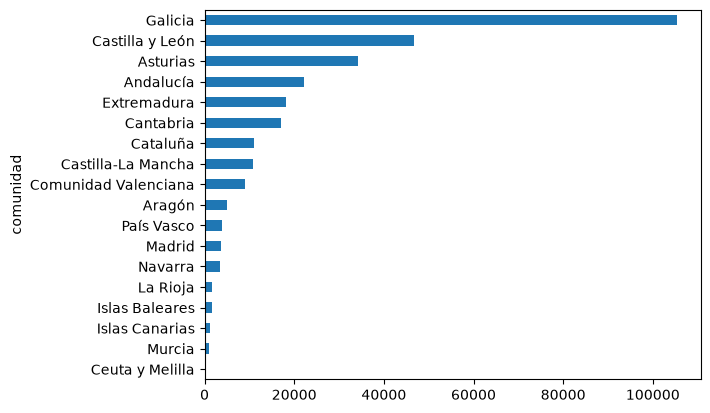

In [185]:
incendios["comunidad"].value_counts(ascending = True).plot(kind = "barh")

La distribución por provincias permite observar diferencias dentro de una misma comunidad autónoma. Comparar los recuentos provinciales ayuda a identificar concentraciones, aunque una comparación más justa del riesgo requeriría tener en cuenta la superficie forestal u otras variables de contexto.

In [186]:
incendios["provincia"].value_counts().head(10)

provincia
Ourense       36929
Asturias      34228
Pontevedra    26868
A Coruña      22472
Lugo          19103
León          17629
Cantabria     17112
Cáceres       11834
Zamora        11365
Badajoz        6358
Name: count, dtype: int64

### Causas registradas

Calculo la distribución de las causas y compruebo qué proporción de registros tiene una causa confirmada. Es importante distinguir entre **causas conocidas, desconocidas y supuestas** antes de extraer conclusiones.

In [187]:
round(incendios["causa"].value_counts() / len(incendios) * 100, 1)

causa
Causa desconocida            51.8
Reproducciones               26.7
Negligencias y accidentes    15.3
Intencionados                 3.3
Causa Natural                 2.2
Otras causas humanas          0.6
Name: count, dtype: float64

In [188]:
round(incendios["confirmacion causa"].value_counts() / len(incendios) * 100, 1)

confirmacion causa
Supuesta      81.4
Confirmada    18.6
Name: count, dtype: float64

La interpretación de las causas presenta incertidumbres: no todos los incendios tienen una causa conocida o confirmada. Para evitar mezclar distintos grados de certeza, preparo un subconjunto con causas confirmadas y excluyo las categorías que no permiten atribuir un origen concreto.

In [189]:
causas_confirmadas = incendios[incendios["confirmacion causa"] == "Confirmada"]

causas_conocidas = causas_confirmadas[(causas_confirmadas["causa"] != "Causa desconocida") & (causas_confirmadas["causa"] != "Reproducciones")]

round(causas_conocidas["causa"].value_counts() / len(causas_conocidas) * 100, 1)

causa
Negligencias y accidentes    53.8
Intencionados                26.8
Causa Natural                12.7
Otras causas humanas          6.7
Name: count, dtype: float64

In [190]:
print("Conocemos la causa confirmada de", len(causas_conocidas), "incendios")

Conocemos la causa confirmada de 19030 incendios


Los porcentajes calculados a partir de las **causas confirmadas y conocidas** describen únicamente ese subconjunto; **no pueden extrapolarse automáticamente a todos los incendios**.

A continuación, examino la distribución mensual para estudiar la estacionalidad.

In [191]:
incendios["mes"].value_counts()

mes
Agosto        60735
Septiembre    49073
Marzo         40179
Julio         35248
Febrero       23494
Abril         21850
Octubre       17617
Junio         15407
Mayo          11083
Enero          9282
Diciembre      6632
Noviembre      5265
Name: count, dtype: int64

In [192]:
round(incendios["mes"].value_counts(normalize = True) * 100, 1)

mes
Agosto        20.5
Septiembre    16.6
Marzo         13.6
Julio         11.9
Febrero        7.9
Abril          7.4
Octubre        6.0
Junio          5.2
Mayo           3.7
Enero          3.1
Diciembre      2.2
Noviembre      1.8
Name: proportion, dtype: float64

<Axes: ylabel='mes'>

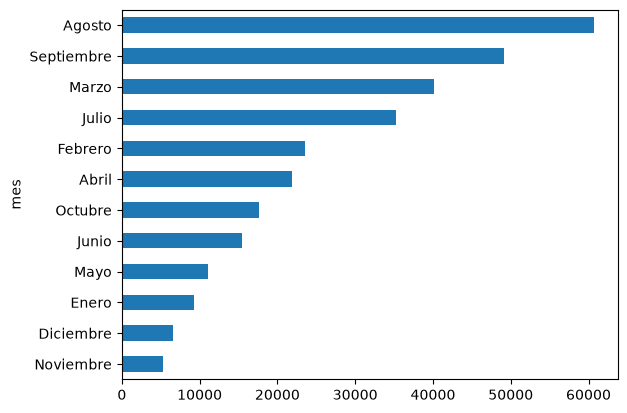

In [193]:
incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

La distribución mensual muestra una concentración importante en **agosto**, aunque también destacan meses fuera del verano. Este resultado invita a distinguir entre **frecuencia de incendios** y **superficie quemada**, que no necesariamente alcanzan sus máximos en los mismos meses.

In [194]:
incendios["año"].value_counts(ascending = False)

año
1989    15922
1995    10145
1985    10119
2000     9338
2005     9006
1981     8762
1990     8413
1994     8280
1997     8183
1998     7937
2002     7816
2004     7640
1991     7450
1992     7336
1978     6955
2001     6920
1988     6743
2003     6620
1999     6483
1987     6454
1980     5856
1996     5775
2009     5770
1986     5665
1984     5614
2011     5593
2006     5589
2012     5530
2017     5222
1979     5060
1993     4983
1982     4899
2008     4351
2015     4120
2010     3907
2019     3826
1976     3463
2007     3407
1983     3404
1975     3266
2014     3194
1974     3154
2013     3083
2021     2896
1973     2887
2020     2700
2022     2520
2016     2432
1970     2289
2018     2012
1977     1554
1972     1535
1968     1450
1971     1236
1969     1078
2023       23
Name: count, dtype: int64

<Axes: xlabel='año'>

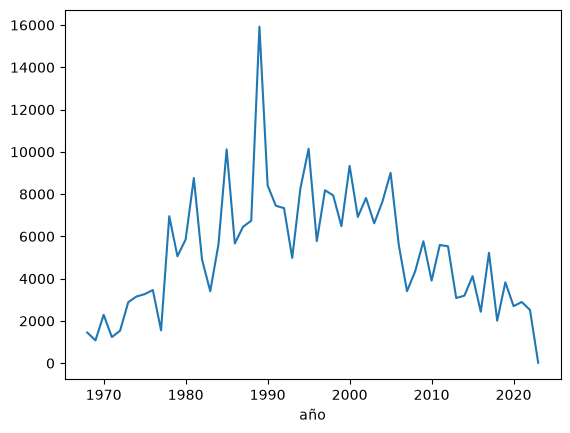

In [195]:
incendios["año"].value_counts().sort_index().plot(kind = "line")

La serie anual permite observar cómo cambia el número de incendios registrados a lo largo del periodo. Conviene interpretar las tendencias con cautela: pueden influir la cobertura del registro, los cambios metodológicos y la variabilidad entre años.

## 7. Comparaciones entre variables

Paso de los recuentos simples a las agrupaciones para comparar territorios, años, meses y causas. Analizo tanto el **número de incendios** como la **superficie total o media quemada**, ya que responden a preguntas distintas.

In [196]:
round(incendios.groupby("comunidad")["provincia"].value_counts(normalize = True) * 100, 1)

comunidad             provincia             
Andalucía             Huelva                     20.5
                      Málaga                     19.2
                      Cádiz                      11.7
                      Jaén                       11.6
                      Sevilla                    10.7
                      Granada                     9.7
                      Córdoba                     9.7
                      Almería                     6.9
Aragón                Zaragoza                   41.6
                      Huesca                     36.1
                      Teruel                     22.3
Asturias              Asturias                  100.0
Cantabria             Cantabria                 100.0
Castilla y León       León                       37.8
                      Zamora                     24.4
                      Burgos                      9.8
                      Salamanca                   8.3
                      Ávila          

Utilizo agrupaciones para estudiar dónde y cuándo se concentra la superficie quemada. Las sumas muestran el impacto acumulado; las medias permiten comparar el tamaño medio de los incendios, aunque pueden verse muy afectadas por casos extremos.

In [197]:
incendios.groupby("comunidad")["hectareas"].sum().sort_values(ascending = False)

comunidad
Galicia                 1.968515e+06
Castilla y León         1.520288e+06
Andalucía               9.012081e+05
Comunidad Valenciana    7.637949e+05
Extremadura             6.161957e+05
Asturias                5.728690e+05
Cataluña                4.903209e+05
Castilla-La Mancha      3.892168e+05
Cantabria               2.777661e+05
Aragón                  2.167522e+05
Islas Canarias          1.430767e+05
Madrid                  6.313391e+04
Islas Baleares          5.063727e+04
País Vasco              4.571640e+04
Navarra                 3.703593e+04
La Rioja                2.778167e+04
Murcia                  1.396151e+04
Ceuta y Melilla         4.345400e+02
Name: hectareas, dtype: float64

In [198]:
incendios.groupby("año")["hectareas"].sum()

año
1968     55389.6000
1969     53000.2000
1970     86929.0000
1971     34104.5000
1972     55563.4000
1973     94443.9000
1974    139273.4000
1975    179729.9000
1976    120965.3000
1977     68664.3000
1978    423742.4000
1979    196852.5500
1980    260978.5000
1981    290579.6000
1982    148597.8000
1983    107175.9000
1984    163755.2000
1985    483843.7000
1986    264276.9000
1987    146692.3000
1988    136607.7000
1989    405892.2000
1990    202489.7000
1991    258953.4000
1992    103348.1000
1993     87424.1000
1994    435383.4000
1995    137608.3200
1996     56718.1600
1997     95560.6900
1998    130013.2900
1999     79474.7900
2000    184574.8500
2001     89797.8200
2002    104848.2800
2003    145644.6500
2004    131075.5800
2005    185141.3700
2006    153117.9500
2007     84661.9300
2008     48627.7000
2009    117844.3500
2010     53176.3200
2011     99610.7000
2012    216496.9500
2013     60044.3300
2014     47154.8700
2015    108096.8000
2016     67971.4800
2017    181648.5

In [199]:
incendios.groupby("año")["hectareas"].sum().sort_values(ascending = False)

año
1985    483843.7000
1994    435383.4000
1978    423742.4000
1989    405892.2000
1981    290579.6000
1986    264276.9000
1980    260978.5000
1991    258953.4000
2022    242436.1565
2012    216496.9500
1990    202489.7000
1979    196852.5500
2005    185141.3700
2000    184574.8500
2017    181648.5512
1975    179729.9000
1984    163755.2000
2006    153117.9500
1982    148597.8000
1987    146692.3000
2003    145644.6500
1974    139273.4000
1995    137608.3200
1988    136607.7000
2004    131075.5800
1998    130013.2900
1976    120965.3000
2009    117844.3500
2015    108096.8000
1983    107175.9000
2002    104848.2800
1992    103348.1000
2011     99610.7000
1997     95560.6900
1973     94443.9000
2021     91377.3686
2001     89797.8200
1993     87424.1000
1970     86929.0000
2019     85076.6705
2007     84661.9300
1999     79474.7900
2020     70243.4206
1977     68664.3000
2016     67971.4800
2013     60044.3300
1996     56718.1600
1972     55563.4000
1968     55389.6000
2010     53176.3

<Axes: xlabel='año'>

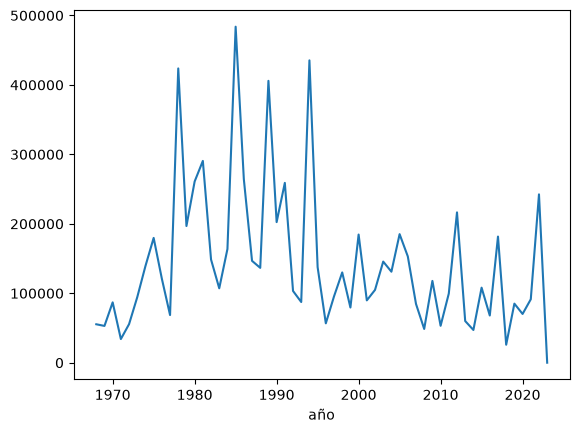

In [200]:
incendios.groupby("año")["hectareas"].sum().plot(kind = "line")

In [201]:
incendios.groupby(["mes"])["hectareas"].sum().sort_values(ascending = False)

mes
Agosto        2.468123e+06
Julio         1.743176e+06
Septiembre    1.339707e+06
Marzo         5.246495e+05
Octubre       4.411880e+05
Junio         3.906204e+05
Febrero       3.234735e+05
Abril         3.158086e+05
Mayo          1.579863e+05
Diciembre     1.549654e+05
Enero         1.413248e+05
Noviembre     9.768200e+04
Name: hectareas, dtype: float64

<Axes: ylabel='mes'>

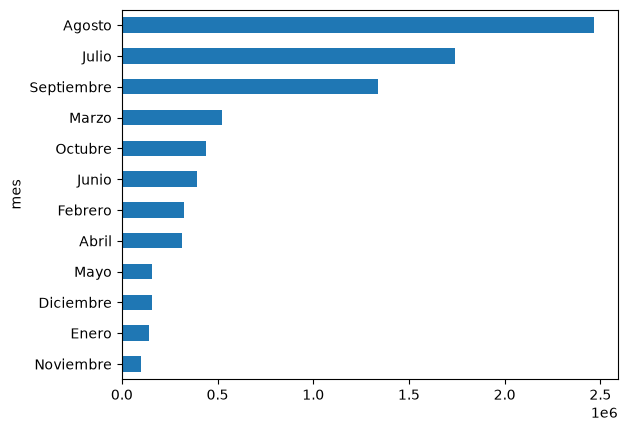

In [202]:
incendios.groupby(["mes"])["hectareas"].sum().sort_values().plot(kind = "barh")

La superficie quemada por mes no sigue necesariamente el mismo patrón que el número de incendios. Esto indica que los meses con más sucesos no tienen por qué ser los que acumulan más hectáreas afectadas.

Para representar correctamente la evolución mensual, también utilizo el **número de mes** como criterio de orden.

<Axes: xlabel='mes'>

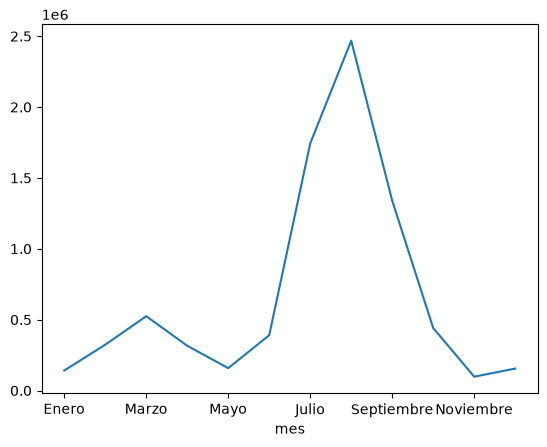

In [203]:
incendios.groupby(["numero mes", "mes"])["hectareas"].sum().sort_index().droplevel(0).plot(kind="line")

In [204]:
incendios.groupby("año")["muertos"].sum()

año
1968     0
1969     0
1970     0
1971     0
1972     0
1973     0
1974     0
1975     0
1976     0
1977     0
1978     0
1979     0
1980     8
1981     4
1982     3
1983    10
1984    20
1985     4
1986     0
1987     1
1988     1
1989     4
1990     5
1991     6
1992    12
1993     3
1994    31
1995     4
1996     1
1997     1
1998     2
1999     5
2000     5
2001     1
2002     1
2003     2
2004     3
2005    16
2006     1
2007     1
2008     0
2009     7
2010     3
2011     9
2012     6
2013     0
2014     2
2015     1
2016     2
2017     2
2018     1
2019     1
2020     4
2021     1
2022     4
2023     0
Name: muertos, dtype: int64

In [205]:
round(incendios.groupby("provincia")["hectareas"].mean(), 1).sort_values(ascending = False)

provincia
Santa Cruz de Tenerife    137.6
Valencia                  116.0
Las Palmas                 92.8
Castellón                  81.7
Albacete                   75.0
Teruel                     57.0
Almería                    56.6
Tarragona                  55.0
Girona                     54.6
Jaén                       53.3
Alicante                   48.3
Cuenca                     47.3
Zaragoza                   46.9
Ciudad Real                46.8
Huelva                     43.9
Barcelona                  43.7
Ávila                      42.0
Salamanca                  42.0
Granada                    39.9
Cáceres                    38.5
Málaga                     37.2
Zamora                     36.3
Cádiz                      35.5
León                       34.2
Guadalajara                33.4
Huesca                     31.7
Sevilla                    31.4
Islas Baleares             31.0
Córdoba                    30.5
Badajoz                    25.2
Segovia                    24.

In [206]:
round(incendios.groupby("causa")["hectareas"].mean(), 1)

causa
Causa Natural                87.6
Causa desconocida            24.2
Intencionados                50.4
Negligencias y accidentes    28.2
Otras causas humanas         26.5
Reproducciones               25.1
Name: hectareas, dtype: float64

## 8. Relaciones entre variables y grandes incendios

Exploro correlaciones entre superficie quemada, personal movilizado, víctimas y pérdidas. Una correlación mide asociación estadística, **no demuestra causalidad**; además, los valores extremos y los registros incompletos pueden influir en el resultado.

In [207]:
print(incendios["hectareas"].corr(incendios["personal"]).round(1))

0.5


In [208]:
print(incendios["hectareas"].corr(incendios["muertos"]).round(1))

0.2


In [209]:
print(incendios["hectareas"].corr(incendios["perdidas"]).round(1))

0.4


In [210]:
print(incendios["gastos"].corr(incendios["perdidas"]).round(1))

0.2


Las correlaciones calculadas son positivas en los pares estudiados, pero deben interpretarse según su magnitud y la calidad de los datos. No sería correcto concluir únicamente a partir de ellas que una mayor superficie quemada **cause** más víctimas, más personal movilizado o mayores pérdidas.

A continuación, represento la relación entre hectáreas y personal para observar la dispersión de los registros.

<Axes: xlabel='hectareas', ylabel='personal'>

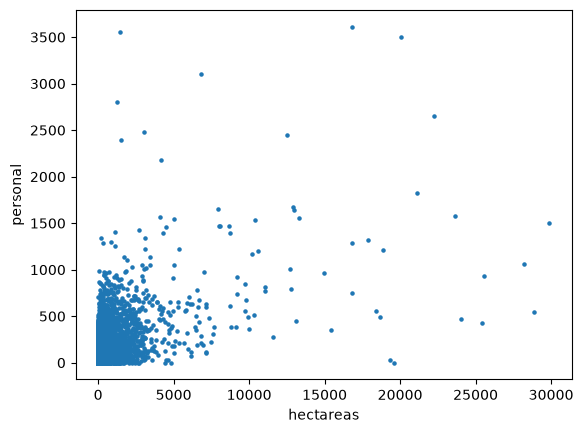

In [211]:
incendios.plot(kind = "scatter", x = "hectareas", y = "personal", s = 5)

El diagrama de dispersión ayuda a observar si existe una tendencia y a identificar incendios atípicos. La nube de puntos puede estar muy concentrada en valores bajos, por lo que conviene evitar conclusiones generales a partir de unos pocos casos extremos.

### Comparación por tamaño del incendio

Divido los registros en dos grupos para comparar su frecuencia, estacionalidad, causas y consecuencias. En el código actual, los **grandes incendios** se definen como aquellos de **500 hectáreas o más**.

**Revisión pendiente del código:** el grupo de pequeños incendios utiliza `<= 500`, por lo que los sucesos de **exactamente 500 hectáreas** pueden aparecer en ambos grupos. Para hacerlos excluyentes habría que usar `< 500` en el segundo filtro.

In [212]:
grandes_incendios = incendios[incendios["hectareas"] >= 500]

grandes_incendios.head(3)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas,impacto economico
4,600.0,1968-01-07,1968,Enero,1,NaN,NaN,NaN,Cataluña,Tarragona,INDETERMINADO,Intencionados,Supuesta,0,0,35,1,0.0,0.0,0.0
404,1500.0,1968-06-30,1968,Junio,6,NaN,NaN,NaN,Extremadura,Cáceres,INDETERMINADO,Reproducciones,Supuesta,0,0,251,3,0.0,0.0,0.0
424,660.0,1968-07-01,1968,Julio,7,NaN,NaN,NaN,Andalucía,Jaén,INDETERMINADO,Intencionados,Supuesta,0,0,19,1,3.0,0.0,3.0


In [ ]:
pequeños_incendios = incendios[incendios["hectareas"] < 500]

pequeños_incendios.head(3)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,personal,medios,gastos,perdidas,impacto economico
0,14.0,1968-01-01,1968,Enero,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Negligencias y accidentes,Supuesta,0,0,0,0,0.0,0.0,0.0
1,3.0,1968-01-03,1968,Enero,1,NaN,NaN,NaN,Cataluña,Tarragona,INDETERMINADO,Reproducciones,Supuesta,0,0,0,0,0.0,0.0,0.0
2,2.0,1968-01-06,1968,Enero,1,NaN,NaN,NaN,Andalucía,Málaga,INDETERMINADO,Reproducciones,Supuesta,0,0,0,0,0.0,0.0,0.0


Con ambos subconjuntos comparo el número de sucesos, su evolución anual, la distribución mensual, las causas y la superficie afectada. También examino las cifras económicas y las víctimas, teniendo presentes las limitaciones de registro ya señaladas.

In [214]:
print("En España han habido",len(grandes_incendios), "grandes incendios y", len(pequeños_incendios), "pequeños incendios")

En España han habido 2162 grandes incendios y 293840 pequeños incendios


<Axes: xlabel='año'>

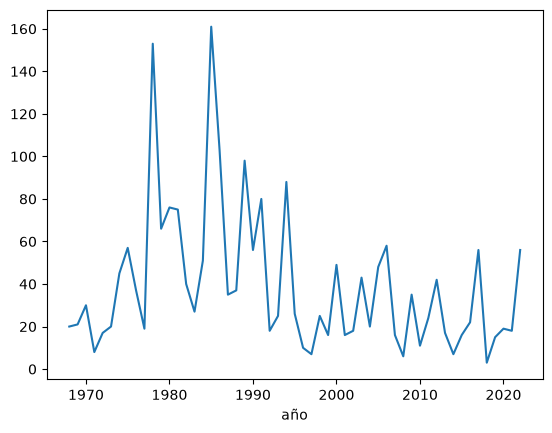

In [215]:
grandes_incendios["año"].value_counts().sort_index().plot(kind = "line")

<Axes: xlabel='año'>

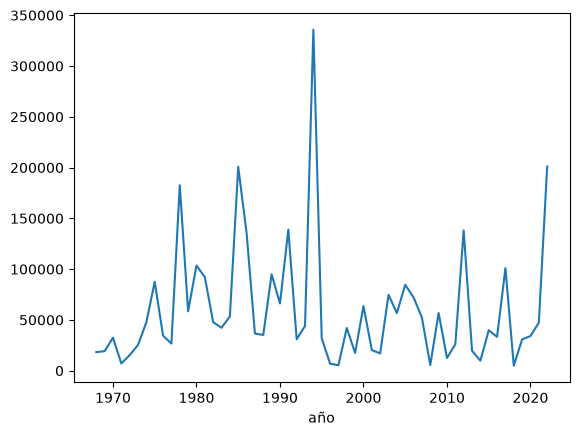

In [216]:
grandes_incendios.groupby("año")["hectareas"].sum().plot(kind = "line")

<Axes: ylabel='mes'>

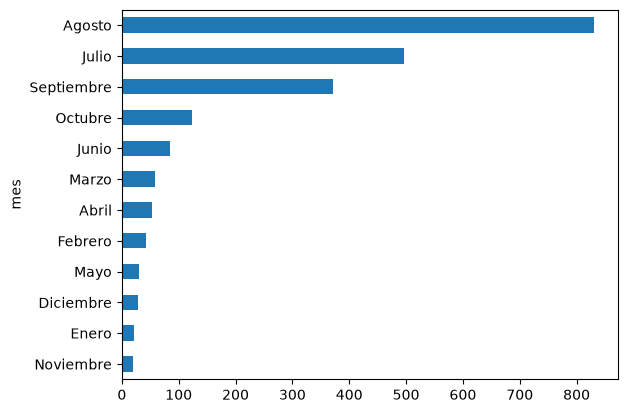

In [217]:
grandes_incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

<Axes: ylabel='mes'>

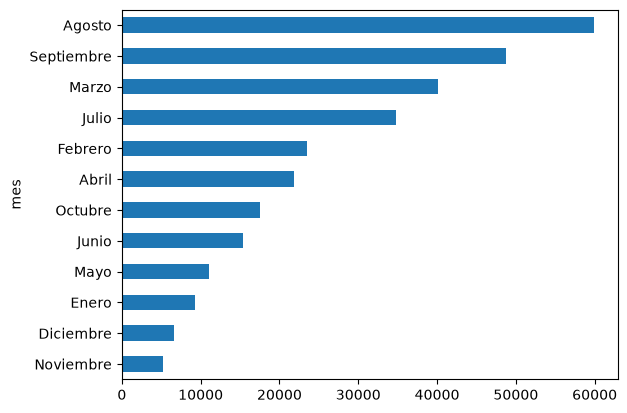

In [218]:
pequeños_incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

In [219]:
round(grandes_incendios["causa"].value_counts() / len(grandes_incendios) * 100, 1)

causa
Causa desconocida            43.2
Reproducciones               26.4
Negligencias y accidentes    16.6
Causa Natural                 6.6
Intencionados                 6.4
Otras causas humanas          0.8
Name: count, dtype: float64

In [220]:
print("Hectáreas quemadas por grandes incendios:", grandes_incendios["hectareas"].sum().round(1), "Hectáreas quemadas por pequeños incendios:", pequeños_incendios["hectareas"].sum().round(1))

Hectáreas quemadas por grandes incendios: 3319269.0 Hectáreas quemadas por pequeños incendios: 4847935.6


In [221]:
print("Impacto economico medio de grandes incendios", grandes_incendios["impacto economico"].mean().round(1), "Impacto economico medio de pequeños incendios", pequeños_incendios["impacto economico"].mean().round(1))

Impacto economico medio de grandes incendios 603681.5 Impacto economico medio de pequeños incendios 4938.5


In [222]:
print("Impacto economico de grandes incendios", grandes_incendios["impacto economico"].sum().round(1), "Impacto economico de pequeños incendios", pequeños_incendios["impacto economico"].sum().round(1))

Impacto economico de grandes incendios 1305159468.0 Impacto economico de pequeños incendios 1451127250.0


In [223]:
print("Muertos en grandes incendios", grandes_incendios["muertos"].sum().round(1), "Muertos en pequeños incendios", pequeños_incendios["muertos"].sum().round(1))

Muertos en grandes incendios 100 Muertos en pequeños incendios 98


La comparación permite valorar el peso de los incendios de gran magnitud frente a los de menor superficie. **Las cifras y proporciones deben actualizarse tras recuperar los registros sin coordenadas y modificar la limpieza**; por eso evito mantener aquí los recuentos de una versión anterior.

Además, los importes económicos son orientativos por la presencia de ceros cuyo significado no siempre está claro. Los resultados de ambos grupos deben interpretarse teniendo en cuenta el posible solapamiento en las 500 hectáreas.

### Representación geográfica exploratoria

Utilizo las coordenadas disponibles para observar la distribución espacial de los incendios y de los grandes incendios. Los registros sin coordenadas se conservan en el análisis general, aunque no pueden aparecer en estas representaciones.

<Axes: title={'center': 'Incendios por comunidad'}, xlabel='longitud', ylabel='latitud'>

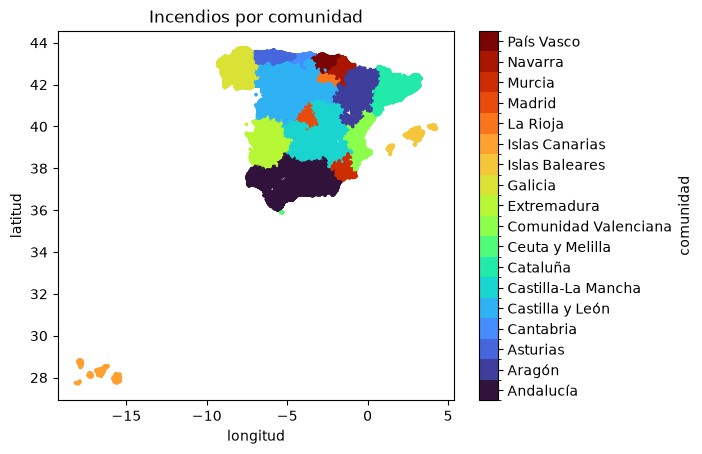

In [224]:
incendios["comunidad"] = incendios["comunidad"].astype("category") 
incendios.plot(kind="scatter", x="longitud", y="latitud", s=3, c="comunidad", colormap="turbo", title="Incendios por comunidad")

<Axes: title={'center': 'Incendios por provincia'}, xlabel='longitud', ylabel='latitud'>

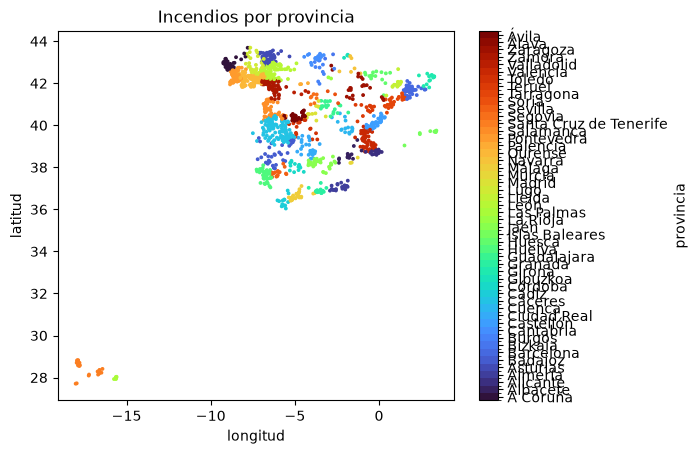

In [225]:
grandes_incendios["provincia"] = grandes_incendios["provincia"].astype("category") 
grandes_incendios.plot(kind="scatter", x="longitud", y="latitud", s=3, c="provincia", colormap="turbo", title="Incendios por provincia")

## 9. Conclusiones y limitaciones

El análisis pone de manifiesto la importancia de estudiar **por separado la frecuencia de los incendios y la superficie quemada**. También muestra diferencias temporales y territoriales que merecen una interpretación cuidadosa, especialmente cuando intervienen incendios excepcionales.

### Limitaciones principales

- **Coordenadas ausentes:** los incendios sin localización siguen contando en las estadísticas, pero no se representan en mapas.
- **Registros idénticos:** se han eliminado filas repetidas, aunque sin un identificador único no es posible confirmar que todos correspondan al mismo suceso.
- **Causas:** una parte de los registros contiene causas desconocidas o no confirmadas.
- **Datos económicos:** los ceros y la falta de homogeneidad histórica limitan las conclusiones sobre costes.
- **Comparación por tamaño:** el código actual incluye las 500 hectáreas en ambos grupos; esta condición debe revisarse antes de presentar resultados definitivos.

### Conclusiones

1. **Impacto de los grandes incendios**

Los grandes incendios, a pesar de ser mucho menos frecuentes, tienen un impacto considerable en la superficie quemada.

Se han registrado 2.162 grandes incendios (de 500 hectáreas o más), que han afectado a 3.319.269 hectáreas, con un impacto económico registrado de 1.305.159.468 euros y un total de 100 fallecidos.

Por otra parte, los 293.703 incendios de menos de 500 hectáreas han afectado a aproximadamente 4.779.436 hectáreas, con un impacto económico registrado de aproximadamente 1.450 millones de euros.

Esto demuestra que un número muy reducido de grandes incendios concentra una parte importante de la superficie total quemada. Las cifras económicas deben interpretarse con precaución debido a las limitaciones de los registros.

2. **Los meses más afectados**

Los meses que acumulan una mayor superficie quemada son agosto, con 2.468.123 hectáreas; julio, con 1.743.176 hectáreas; y septiembre, con 1.339.707 hectáreas.

Estos resultados muestran una clara concentración de la superficie quemada durante los meses de verano, especialmente en agosto.

3. **Distribución geográfica**

Las comunidades autónomas que concentran un mayor porcentaje de incendios son Galicia (35,6 %), Castilla y León (15,8 %) y Asturias (11,6 %).

Por otra parte, la provincia con mayor superficie media quemada por incendio es Santa Cruz de Tenerife, con aproximadamente 137,6 hectáreas por incendio.

Esto demuestra que las zonas con más incendios no tienen por qué ser las que presentan una mayor superficie media afectada por cada suceso.

4. **Evolución histórica**

En términos generales, el número de incendios ha disminuido respecto a las décadas de mayor actividad del siglo pasado. La evolución de la superficie quemada también presenta importantes diferencias entre periodos, aunque sigue habiendo años con incendios especialmente graves.

Destaca 2022, con 242.436 hectáreas quemadas, como el año con mayor superficie afectada del siglo XXI dentro de los registros analizados.

Por tanto, aunque la evolución histórica muestra una reducción general de los incendios, siguen produciéndose episodios de gran magnitud que provocan daños importantes.

## 10. Limpiar los datos

Finalmente, exporto los datos preparados para su uso posterior.

In [226]:
incendios.to_csv("datos/incendios_limpios.csv", index=False)

In [227]:
grandes_incendios.to_csv("datos/grandes_limpios.csv", index=False)